# How much value does a used car keep?
### Claire Carroll, Ben Parrack, Caitlin Brogden

We use the DVM-CAR dataset to predict a car's value retention ratio:

retention = advertised used price / entry-level new price of the same model in its registration year


## 1. Loading the data/Data Quantity

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ad = pd.read_csv("data/Ad_table (extra).csv", low_memory=False)
price = pd.read_csv("data/Price_table.csv")
ad.columns = ad.columns.str.strip()  # some column names in this file start with a space

print("ad table:", ad.shape)
print("price table:", price.shape)
print("car models in ads:", ad["Genmodel_ID"].nunique(), "| with a new price:", price["Genmodel_ID"].nunique())
ad.head()

ad table: (268255, 24)
price table: (6333, 5)
car models in ads: 881 | with a new price: 647


,Maker,Genmodel,Genmodel_ID,Adv_ID,Adv_year,Adv_month,Color,Reg_year,Bodytype,Runned_Miles,...,Engine_power,Annual_Tax,Wheelbase,Height,Width,Length,Average_mpg,Top_speed,Seat_num,Door_num
0,Bentley,Arnage,10_1,10_1$$1,2018,4,Silver,2000.0,Saloon,60000,...,NaN,NaN,3116.0,1515.0,2125.0,5390.0,NaN,NaN,5.0,4.0
1,Bentley,Arnage,10_1,10_1$$2,2018,6,Grey,2002.0,Saloon,44000,...,450.0,315,3116.0,1515.0,2125.0,5390.0,13.7 mpg,179 mph,5.0,4.0
2,Bentley,Arnage,10_1,10_1$$3,2017,11,Blue,2002.0,Saloon,55000,...,400.0,315,3116.0,1515.0,2125.0,5390.0,14.7 mpg,155 mph,5.0,4.0
3,Bentley,Arnage,10_1,10_1$$4,2018,4,Green,2003.0,Saloon,14000,...,NaN,NaN,3116.0,1515.0,2125.0,5390.0,NaN,NaN,5.0,4.0
4,Bentley,Arnage,10_1,10_1$$5,2017,11,Grey,2003.0,Saloon,61652,...,NaN,NaN,3116.0,1515.0,2125.0,5390.0,NaN,NaN,5.0,4.0


## 2. Data Quality

### 2.1 Column types

In [2]:
ad.dtypes

Maker               str
Genmodel            str
Genmodel_ID         str
Adv_ID              str
Adv_year          int64
Adv_month         int64
Color               str
Reg_year        float64
Bodytype            str
Runned_Miles        str
Engin_size          str
Gearbox             str
Fuel_type           str
Price           float64
Engine_power    float64
Annual_Tax          str
Wheelbase       float64
Height          float64
Width           float64
Length          float64
Average_mpg         str
Top_speed           str
Seat_num        float64
Door_num        float64
dtype: object

#### Many columns that should be numbers are strings, so we need to to transform that data

### 2.2 Missing values

In [3]:
print("% Percent of missing values")
(ad.isna().mean() * 100).round(1).sort_values(ascending=False)

% Percent of missing values


Annual_Tax      17.4
Top_speed       16.3
Average_mpg     15.6
Engine_power    11.9
Width           10.5
Length          10.4
Wheelbase       10.4
Height          10.4
Color            8.2
Seat_num         2.4
Door_num         1.7
Engin_size       0.8
Runned_Miles     0.4
Price            0.4
Bodytype         0.4
Fuel_type        0.2
Gearbox          0.1
Reg_year         0.0
Adv_year         0.0
Adv_month        0.0
Genmodel         0.0
Genmodel_ID      0.0
Maker            0.0
Adv_ID           0.0
dtype: float64

#### Lots of columns are clean and have no missing data while some need a lot of cleaning done. Interestingely .4% of rows are missing a price, which means they are useless for our project and we will need to drop those rows. Also below we calculate the total number of missing values in our dataset.

In [4]:
print("Total missing values: ", ad.isna().sum().sum())
print("Total rows with missing values: ", ad.isna().any(axis=1).sum())

Total missing values:  314404
Total rows with missing values:  80073


### 2.3 Duplicates

In [5]:
print("same Adv_ID twice:", ad["Adv_ID"].duplicated().sum())
print("same car listed twice (every column equal except Adv_ID):", ad.drop(columns="Adv_ID").duplicated().sum())

same Adv_ID twice: 0
same car listed twice (every column equal except Adv_ID): 889


#### No ad ID repeats, but 889 ads match another ad in every column. That just means it's the same car listed again, so we'll delete the duplicate copies so they're no repeats.

### 2.4 Ad year

In [6]:
ad["Adv_year"].value_counts().sort_index()

Adv_year
2012         3
2013         7
2014        27
2015       105
2016       581
2017     11320
2018    239973
2019       107
2020      1268
2021     14864
Name: count, dtype: int64

#### This shows that our data has a really uneven time based split, so when training on the data we can't just split evenly by year we will have to manually choose what years to train, validate, and test on.

### 2.5 Price outliers

In [7]:
print(ad["Price"].describe())
print(ad["Price"].nlargest(5))
ad[ad["Price"] < 300][["Maker", "Genmodel", "Reg_year", "Runned_Miles", "Price"]].sample(8, random_state=1)

count    2.671100e+05
mean     1.475626e+04
std      3.232091e+04
min      1.000000e+02
25%      4.990000e+03
50%      9.299000e+03
75%      1.715000e+04
max      9.999999e+06
Name: Price, dtype: float64
104958    9999999.0
14460     2599990.0
14462     2500000.0
105002    2490000.0
14276     2200000.0
Name: Price, dtype: float64


,Maker,Genmodel,Reg_year,Runned_Miles,Price
91548,Lexus,IS 220d,2006.0,120000,123.0
49289,Honda,Jazz,2002.0,80000,299.0
32275,Ford,Focus C-Max,2004.0,159000,290.0
220538,Toyota,Yaris,2000.0,80000,250.0
6784,Citroen,Saxo,2003.0,104480,250.0
140694,Peugeot,206,2000.0,80000,275.0
28886,Ford,Focus,2004.0,145000,290.0
24043,Ford,Fiesta,2003.0,82204,230.0


#### At the top end of our data we have pricec of £9,999,999 and £999,999 which are very likely placeholder prices, so we drop them. There are other £1–2.6 M ads which are most likely real supercars so we keep them.
#### At the bottom end there are a few ads for under £300 which are mostly 15–20-year-old Fiestas, Micras and Puntos with 80–160k miles. These are just real low priced cars, so we keep these.

## 3. Clean and join

To transform and clean data:
- Drop the duplicate ads
- Drop ads with no price
- Drop the placeholder prices
- Join each ad to its model's new price in the year it was registered
- Work out the car's age when it was advertised

In [8]:
ad = ad.drop_duplicates(subset=ad.columns.drop("Adv_ID"))
ad = ad.dropna(subset=["Price"])
ad = ad[~ad["Price"].isin([999999, 9999999])]

df = ad.merge(price[["Genmodel_ID", "Year", "Entry_price"]], left_on=["Genmodel_ID", "Reg_year"], right_on=["Genmodel_ID", "Year"])
print("ads matched to a new price:", round(len(df) / len(ad) * 100, 1), "%")

df["age"] = df["Adv_year"] - df["Reg_year"]
print("negative ages dropped:", (df["age"] < 0).sum())
df = df[df["age"] >= 0]
df["retention"] = df["Price"] / df["Entry_price"]

print("usable ads:", len(df), "| car models:", df["Genmodel_ID"].nunique())

ads matched to a new price: 83.9 %
negative ages dropped: 74
usable ads: 223216 | car models: 582


#### This shows that 83.9% of cars listed in ads match to a new car price, meaning those are usable for our project and we can calculate a value retention ratio for them ("retention")

## 4. The target

#### In this section we'll showcase our retention target variable, which we calculated ourselves from the cleaned and joined data table

In [9]:
df["retention"].describe()

count    223216.000000
mean          0.569699
std           0.331724
min           0.005597
25%           0.314391
50%           0.538352
75%           0.779416
max           8.541267
Name: retention, dtype: float64

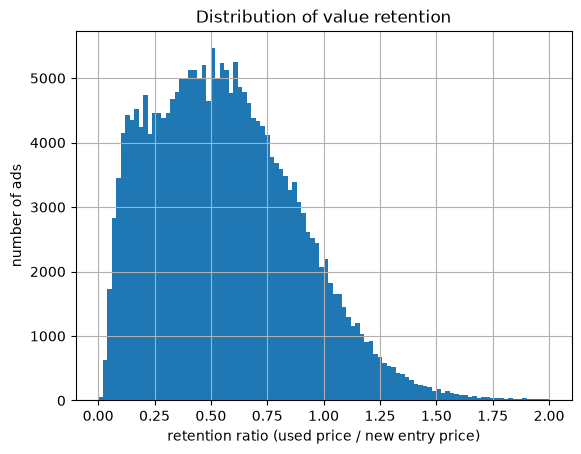

In [10]:
df["retention"].hist(bins=100, range=(0, 2))
plt.xlabel("retention ratio (used price / new entry price)")
plt.ylabel("number of ads")
plt.title("Distribution of value retention")
plt.show()

#### This shows that the median car is advertised at ~54% of its model's new entry price, with a long tail to the right showing outliers.

In [11]:
df.to_csv("data/cars_joined.csv", index=False)